# Make your own weather forecast map 🌧️
### ECMWF free & open data · 9 km · over Bulgaria

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/bulgaria_forecast.ipynb)

Everything here uses **free, open data** from ECMWF and open-source Python. In a few cells you'll
pull today's **9 km** forecast, bin it into hexagons, and draw a map of **rainfall over Bulgaria**.

Then change one line and make it for **your** country, day, or variable.

*In Google Colab? Press **Runtime → Run all**. Nothing to install on your own computer.*

In [1]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q ecmwf-opendata earthkit-data cfgrib eccodes cartopy shapely h3

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import matplotlib.cm as mcm
from matplotlib.collections import PolyCollection
from matplotlib.colors import PowerNorm, Normalize
import cartopy.crs as ccrs
import cartopy.io.shapereader as shpreader
from shapely.geometry import Point
from shapely.prepared import prep
import h3
import earthkit.data as ekd
from ecmwf.opendata import Client

## 1 · Choose what to map

`DATE = 0` means **today's** forecast. `STEP` is how many hours ahead.
Change `COUNTRY`, `CAPITAL`, or `STEP` and re-run to make a different map.

In [3]:
COUNTRY = "Bulgaria"
CAPITAL = ("Sofia", 42.698, 23.322)        # name, lat, lon
DATE    = 0                                # 0 = today's 00Z run
STEP    = 48                               # hours ahead
PARAM   = "tp"                             # "tp" = rainfall, "2t" = temperature
BBOX    = (22.0, 29.0, 41.0, 44.5)         # W, E, S, N around the country
EXTENT  = [22.2, 28.7, 41.1, 44.3]
RES     = 5                                # H3 hexagon size (res 5 ~ 9 km, matching the model)

## 2 · Get the forecast (ECMWF open data, 9 km)

One request to ECMWF's open-data service at 0.1° (~9 km). `resol="0p1"` is the important bit —
the default is coarser (0.25°).

In [4]:
Client("ecmwf").retrieve(date=DATE, time=0, step=STEP, stream="oper", type="fc",
                         levtype="sfc", param=PARAM, resol="0p1", target="data.grib2")

ds = ekd.from_source("file", "data.grib2")       # read it with earthkit
x = ds.to_xarray().squeeze()
lon = ((x["longitude"].values + 180) % 360) - 180
lat = x["latitude"].values
data = x[list(x.data_vars)[0]].values            # the field we requested
field = data * 1000.0                            # metres -> millimetres
print(f"Rainfall up to {field.max():.0f} mm over the next {STEP} h")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Rainfall up to 628 mm over the next 48 h


## 3 · Bin into hexagons and keep only the country

In [5]:
shp = shpreader.natural_earth(resolution="10m", category="cultural", name="admin_0_countries")
country = next(r.geometry for r in shpreader.Reader(shp).records()
               if r.attributes.get("NAME") == COUNTRY)
inside = prep(country)

m = ((lon >= BBOX[0]) & (lon <= BBOX[1]))
n = ((lat >= BBOX[2]) & (lat <= BBOX[3]))
LON, LAT = np.meshgrid(lon[m], lat[n])
V = field[np.ix_(n, m)]

agg = {}
for la, lo, v in zip(LAT.ravel(), LON.ravel(), V.ravel()):
    c = h3.latlng_to_cell(float(la), float(lo), RES)
    s = agg.setdefault(c, [0.0, 0]); s[0] += float(v); s[1] += 1
cells, vals = [], []
for c, (s, k) in agg.items():
    clat, clon = h3.cell_to_latlng(c)
    if inside.contains(Point(clon, clat)):
        cells.append(c); vals.append(s / k)
vals = np.array(vals)
print(f"{len(cells)} hexagons across {COUNTRY}")

406 hexagons across Bulgaria


## 4 · Draw the map

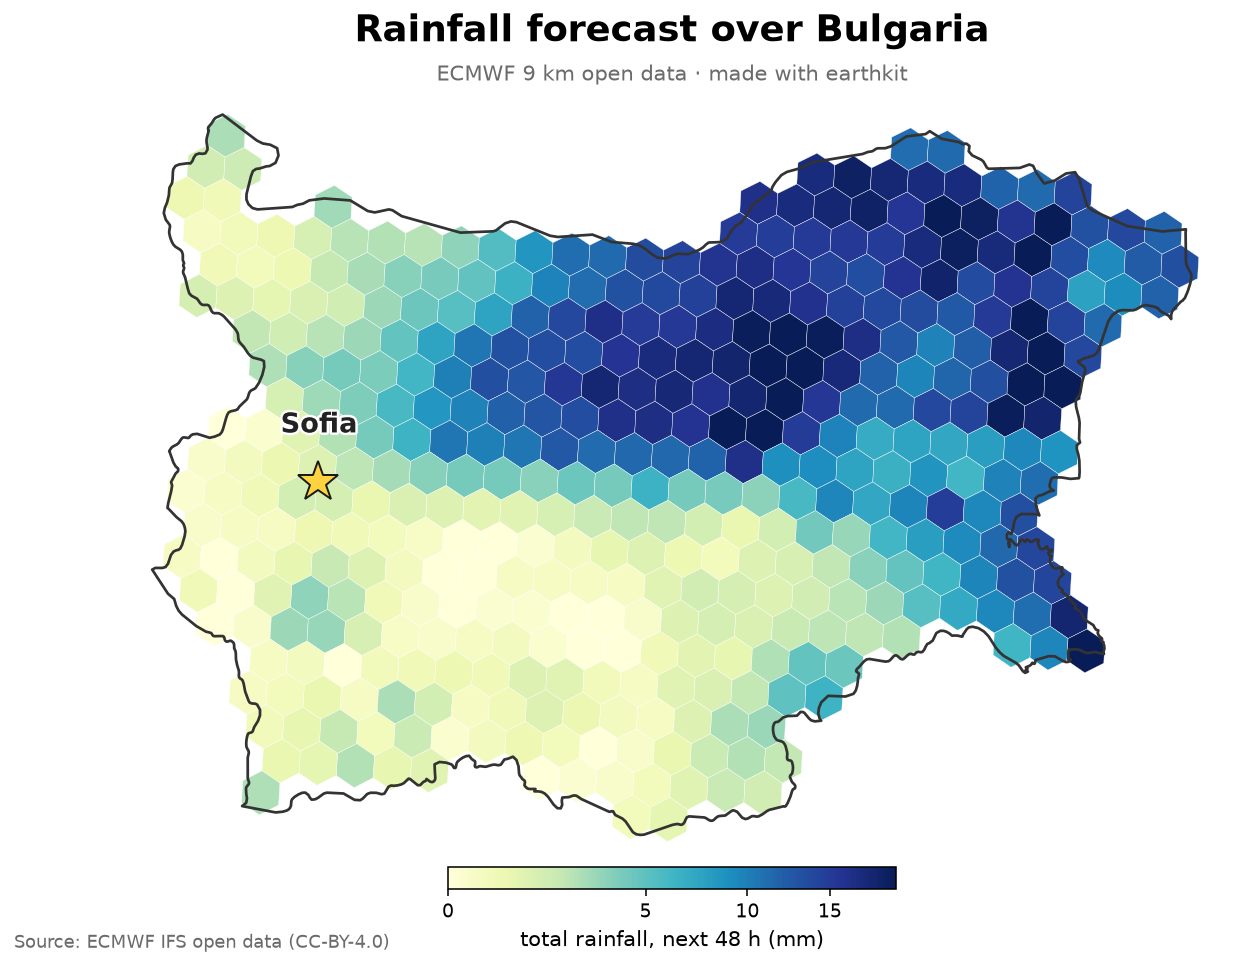

In [6]:
cmap = plt.get_cmap("YlGnBu")
norm = PowerNorm(0.6, vmin=0, vmax=max(np.percentile(vals, 97), 1.0))
clabel = f"total rainfall, next {STEP} h (mm)"
title = f"Rainfall forecast over {COUNTRY}"
polys = [[(p[1], p[0]) for p in h3.cell_to_boundary(c)] for c in cells]

proj = ccrs.AlbersEqualArea(central_longitude=(BBOX[0]+BBOX[1])/2, central_latitude=(BBOX[2]+BBOX[3])/2)
fig = plt.figure(figsize=(10, 7), dpi=140)
ax = fig.add_axes([0.03, 0.12, 0.94, 0.78], projection=proj)
ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
try: ax.spines["geo"].set_visible(False)
except Exception: pass
ax.add_collection(PolyCollection(polys, transform=ccrs.PlateCarree(),
                  facecolors=cmap(norm(vals)), edgecolors="white", linewidths=0.2))
ax.add_geometries([country], crs=ccrs.PlateCarree(), facecolor="none",
                  edgecolor="#333333", linewidth=1.4, zorder=5)
name, clat, clon = CAPITAL
ax.plot(clon, clat, marker="*", ms=22, color="#ffd23f", mec="#1a1a1a", mew=1.0,
        transform=ccrs.PlateCarree(), zorder=10)
ax.text(clon, clat + 0.18, name, transform=ccrs.PlateCarree(), ha="center", va="bottom",
        fontsize=14, fontweight="bold", color="#222",
        path_effects=[pe.withStroke(linewidth=2.5, foreground="white")], zorder=11)

cax = fig.add_axes([0.34, 0.09, 0.32, 0.022])
cb = fig.colorbar(mcm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal")
cb.set_label(clabel, fontsize=11)
fig.text(0.5, 0.955, title, ha="center", fontsize=19, fontweight="bold")
fig.text(0.5, 0.915, "ECMWF 9 km open data · made with earthkit", ha="center", color="#6b6b6b", fontsize=11)
fig.text(0.03, 0.03, "Source: ECMWF IFS open data (CC-BY-4.0)", color="#6b6b6b", fontsize=9)
fig.savefig(f"{COUNTRY.lower()}_map.png", bbox_inches="tight")
plt.show()

## 5 · Your turn 🌍

- **Different country?** Change `COUNTRY` and `CAPITAL` (widen `BBOX` for a bigger country), then Run all.
- **Different day?** Change `STEP` (24, 72, 120 …).
- **Different weather?** Set `PARAM = "tp"` for rainfall or `"2t"` for temperature (temperature is in
  kelvin — subtract 273.15 instead of multiplying by 1000 in step 2).

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) ·
[earthkit](https://earthkit-data.readthedocs.io) · [ecmwf-opendata](https://github.com/ecmwf/ecmwf-opendata)